In [25]:
import torch
import numpy
from matplotlib import pyplot

import importlib
import velocity_model
import estimate_velocity
importlib.reload(velocity_model)
importlib.reload(estimate_velocity)

L = 5e6
Growthrate = torch.tensor([1/(20*60)], dtype=torch.double)
v0 = 1e3
Tr = L/(2*v0)
origins = torch.tensor([2e6, 4e6], dtype=torch.int32)
delay = torch.tensor([360.0, 0.0], dtype=torch.double)
h_tgrid = torch.linspace(0, 0.6*Tr, steps=11, dtype=torch.double)
g_xranges_l = torch.tensor([1e6, 4.5e6], dtype=torch.int32)
g_xranges_u = torch.tensor([1.1e6, 4.6e6], dtype=torch.int32)

mtrue = velocity_model.VelocityModel(L, True, origins, h_tgrid, g_xranges_l, g_xranges_u)
mtrue.growthrate = Growthrate
mtrue.delay = delay
mtrue.v0 = torch.tensor([v0], dtype=torch.double)
mtrue.h_log_raw = torch.log(torch.tensor([1, 1, 1.5, 2, 1.5, 1, 0.5, 0.1, 0.5, 1, 1], dtype=torch.double))
mtrue.g_log = torch.log(torch.tensor([10, 0.1], dtype=torch.double))

coverage = 1e3
x = torch.linspace(0, L, steps=1000)
y_obs = torch.poisson(mtrue.P(x) * coverage).detach().numpy()
s_obs = numpy.sqrt(y_obs)

In [26]:
h_tgrid_dense = torch.linspace(0, Tr, steps=1000, dtype=torch.double)
m = velocity_model.VelocityModel(L, True, origins, h_tgrid_dense, g_xranges_l, g_xranges_u)
m.growthrate = Growthrate
m.h_sigma = torch.tensor([1], dtype=torch.double)
m.h_timescale = torch.nn.Parameter(torch.tensor([50], dtype=torch.double))

#torch.autograd.set_detect_anomaly(True)
l = velocity_model.VelocityModelLoss(x, torch.tensor(y_obs), torch.tensor(s_obs), m)
fit = estimate_velocity.FitVelocityModel(m, l)
fit.optimize_parameters()

Text(0, 0.5, 'abundance [reads]')

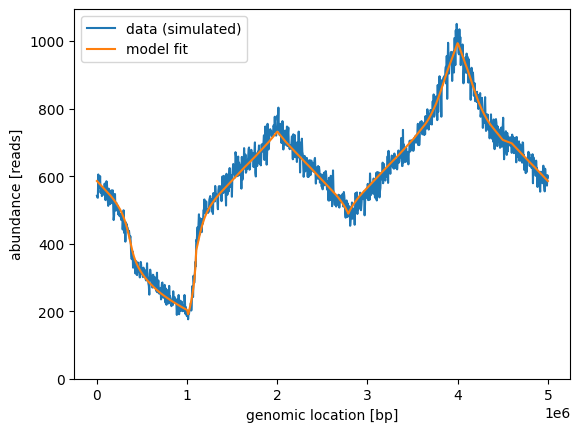

In [27]:
pyplot.plot(fit.loss.x, fit.loss.y_obs.detach(), label="data (simulated)")
pyplot.plot(fit.loss.x, fit.loss.y_pred().detach(), label="model fit")
pyplot.legend()
pyplot.ylim(ymin=0)
pyplot.xlabel("genomic location [bp]")
pyplot.ylabel("abundance [reads]")

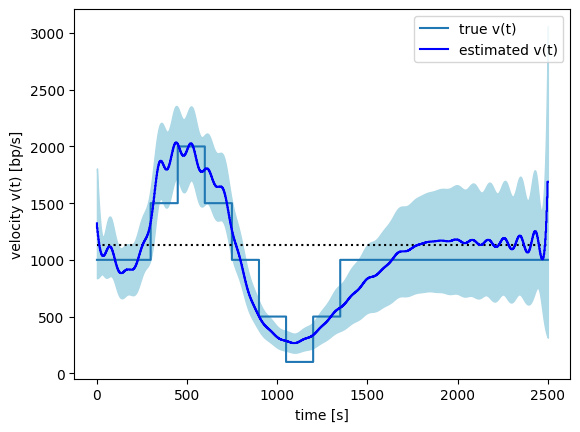

In [29]:
pyplot.step(h_tgrid_dense, mtrue.v_t(h_tgrid_dense).detach(), label="true v(t)")
p_cov, p_pmap = fit.parameter_posterior_cov()
i, l = p_pmap[id(m.h_log_raw)], torch.numel(m.h_log_raw)
v_t = m.v_t(fit.model.h_tgrid).detach()
v_t_stderr = m.v_t_posterior_stderr(fit.model.h_tgrid, p_cov, p_pmap).detach()
pyplot.hlines([m.v0.detach()], xmin=0, xmax=m.h_tgrid.max(),
              linestyle="dotted", color="black")
pyplot.step(h_tgrid_dense, v_t, label="estimated v(t)", color="blue")
pyplot.fill_between(h_tgrid_dense,  v_t - v_t_stderr, v_t + v_t_stderr, color="lightblue")
pyplot.xlabel("time [s]")
pyplot.ylabel("velocity v(t) [bp/s]")
pyplot.legend()